# 역할별 메시지와 제약

**이 노트북에서 할 일**

1. 공통 지시·과업 제약·고객 문의를 세 글로 나누고, 한 메시지 목록과 역할별 목록을 만듭니다.
2. 두 목록을 같은 모델에 보내 답 원문, 토큰 수, 걸린 초를 같은 기록 모양으로 비교합니다.
3. 고객 문의에 규정에 없는 요구를 더해, 확인 단어만으로는 답을 판정할 수 없다는 것을 봅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

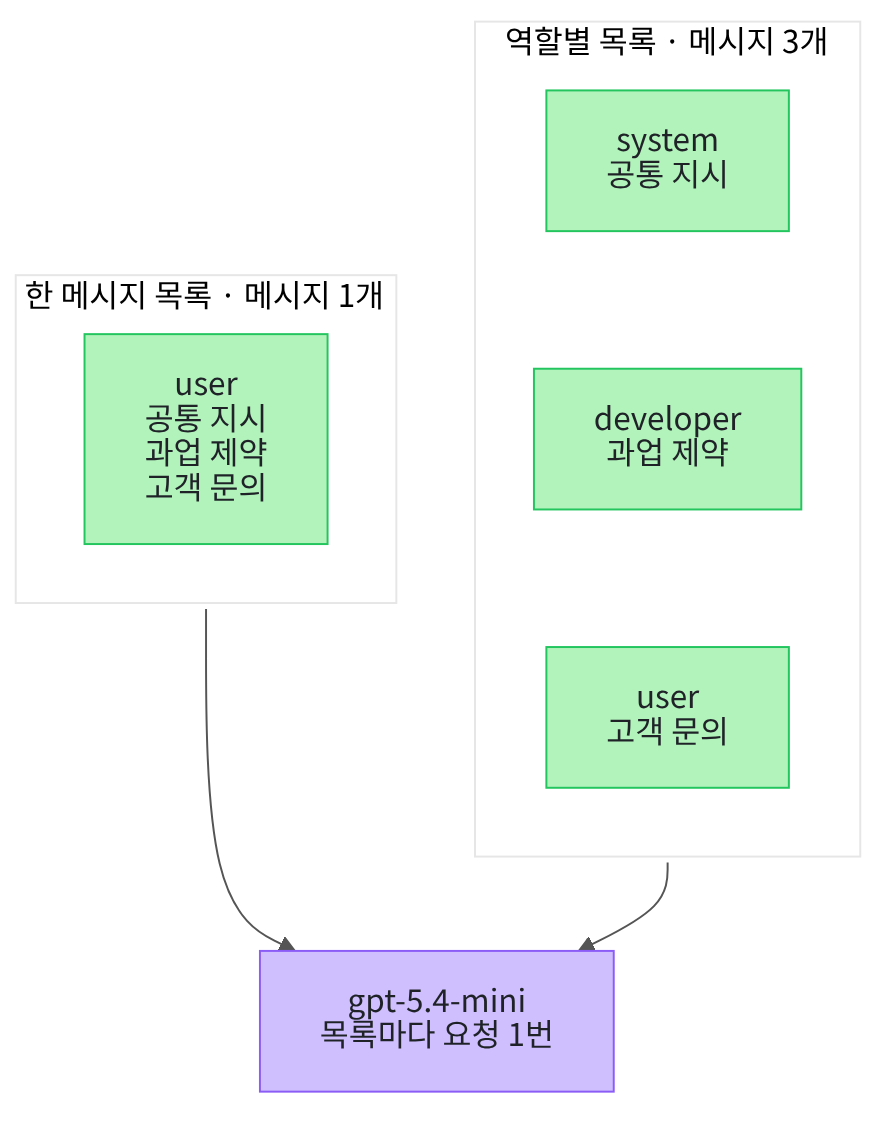

위에서 아래로 읽습니다. 왼쪽 칸은 세 글을 user 메시지 하나에 이어 붙인 목록입니다.
오른쪽 칸은 같은 세 글을 system·developer·user 역할에 하나씩 넣은 목록입니다.
두 목록은 아래 보라 상자의 같은 모델로 한 번씩 보냅니다. 글자는 같고 역할 배치만 다릅니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
Ch 6과 같은 판이지만, 이 챕터는 실습 폴더가 따로 있어 한 번 더 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

걸린 시간을 재는 모듈 `time`(Ch 6 05절)과 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

Ch 6과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
Ch 6과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 세 가지 글 나누기

고객 지원 요청에는 성격이 다른 글 세 가지가 섞여 있습니다. 모든 문의에 쓰는 담당자 역할과 회사 규정이 있습니다.
이번 답변이 지킬 조건이 있고, 고객마다 달라지는 문의가 있습니다. 이 셋을 먼저 이름이 다른 변수에 나눠 담습니다.

이름 `policy_text`는 공통 지시, `constraint_text`는 과업 제약, `inquiry_text`는 고객 문의입니다.
과업 제약(constraint)은 답이 지켜야 할 조건입니다. 택배 상자에 붙이는 「깨지기 쉬움, 위로 쌓지 마세요」 쪽지와 비슷합니다.

In [5]:
# 모든 문의에 쓰는 공통 지시, 이번 답의 과업 제약, 고객 문의를 세 글로 나눕니다
policy_text = "당신은 전자상거래 고객 지원 분류기입니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다."
constraint_text = "근거 없는 보상은 약속하지 마세요. 분류, 필요한 다음 행동, 고객에게 보낼 한 문장을 짧게 답하세요."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
print("공통 지시:", policy_text)
print("과업 제약:", constraint_text)
print("고객 문의:", inquiry_text)

공통 지시: 당신은 전자상거래 고객 지원 분류기입니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다.
과업 제약: 근거 없는 보상은 약속하지 마세요. 분류, 필요한 다음 행동, 고객에게 보낼 한 문장을 짧게 답하세요.
고객 문의: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.


**결과 읽기** — 세 줄은 `공통 지시:`, `과업 제약:`, `고객 문의:`로 시작합니다. 고객 문의 줄에는 주문번호 `A-1042`가 있습니다.
아직 글만 만들었고 요청은 보내지 않았습니다.

## 3. 한 메시지 목록 만들기

첫 번째 목록은 세 글을 이어 붙여 user 메시지 하나에 넣습니다. 글 `"\n"`은 줄바꿈 한 번입니다.
Ch 6에서 쓴 튜플 목록 모양 그대로, 목록에 튜플이 하나만 있습니다.

실행 전에 예상합니다. 메시지 수는 1이고, user 내용은 세 줄일 것입니다.

In [6]:
# 세 글을 줄바꿈으로 이어 user 메시지 하나에 넣습니다(요청은 보내지 않습니다)
merged_text = policy_text + "\n" + constraint_text + "\n" + inquiry_text
merged_messages = [("user", merged_text)]
print("한 메시지 목록의 메시지 수:", len(merged_messages))
print("user 메시지 내용:")
print(merged_text)

한 메시지 목록의 메시지 수: 1
user 메시지 내용:
당신은 전자상거래 고객 지원 분류기입니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다.
근거 없는 보상은 약속하지 마세요. 분류, 필요한 다음 행동, 고객에게 보낼 한 문장을 짧게 답하세요.
어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.


**결과 읽기** — 첫 줄은 `한 메시지 목록의 메시지 수: 1`입니다. 라벨 줄 아래 세 줄이 user 메시지 하나의 내용입니다.
공통 지시·과업 제약·고객 문의가 한 메시지 안에서 줄만 바뀌어 이어집니다.

## 4. 역할별 목록 만들기

두 번째 목록은 같은 세 글을 역할 세 개에 하나씩 넣습니다. 공통 지시는 system, 고객 문의는 user입니다.
과업 제약은 developer 역할에 넣습니다. 개발자 메시지(developer message)는 앱을 만든 사람의 지시를 담는 OpenAI API의 역할입니다.

OpenAI 안내서는 developer 메시지를 user 메시지보다 먼저 따른다고 설명합니다. 이 역할이 LangChain 안에서 어떤 모양이 되는지는 5절에서 봅니다.
실행 전에 예상합니다. 역할 이름 세 줄이 순서대로 나올 것입니다.

In [7]:
# 같은 세 글을 system·developer·user 역할에 하나씩 넣습니다(요청은 보내지 않습니다)
layered_messages = [
    ("system", policy_text),
    ("developer", constraint_text),
    ("user", inquiry_text),
]
print("역할별 목록:")
for role, content in layered_messages:
    print(role, "|", content)

역할별 목록:
system | 당신은 전자상거래 고객 지원 분류기입니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다.
developer | 근거 없는 보상은 약속하지 마세요. 분류, 필요한 다음 행동, 고객에게 보낼 한 문장을 짧게 답하세요.
user | 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `system |`, `developer |`, `user |`로 시작합니다.
두 목록이 다른 것은 역할 배치뿐이어야 합니다. 비교할 때 지시 글자까지 달라지면, 답이 달라진 이유를 나눌 수 없기 때문입니다.

그래서 역할별 목록의 내용을 다시 이어 붙여, 한 메시지 목록의 글과 같은지 확인합니다.
Ch 1에서 배운 인덱싱을 `layered_messages[0][1]`처럼 두 번 쓰면, 첫 튜플의 둘째 값인 내용을 꺼냅니다.
글이 같아야 하는 값이라 마지막 줄의 `assert`로 확인합니다.

In [8]:
# 역할별 목록의 내용을 다시 이어 붙여, 한 메시지 목록의 글과 글자까지 같은지 확인합니다
first_content = layered_messages[0][1]
second_content = layered_messages[1][1]
third_content = layered_messages[2][1]
layered_joined = first_content + "\n" + second_content + "\n" + third_content
same_text = layered_joined == merged_text
print("두 목록의 글이 같은가:", same_text)
assert same_text

두 목록의 글이 같은가: True


**결과 읽기** — 출력 줄은 `두 목록의 글이 같은가: True`입니다. `assert`도 통과했습니다.
이제 두 목록은 지시 글자는 같고, 역할 배치만 다릅니다.

## 5. developer 튜플은 무엇이 될까

Ch 6 02절에서 튜플 목록은 `invoke()` 안에서 메시지 객체로 바뀐다고 했습니다. 이번에는 그 변환을 직접 불러 봅니다.
함수 `convert_to_messages()`는 튜플 목록을 받아 메시지 객체 목록을 반환합니다. 설치한 langchain-core 1.6.2에서 `invoke()`가 요청 전에 부르는 함수입니다.

속성 `additional_kwargs`는 메시지 객체에 덧붙인 추가 정보 딕셔너리입니다. 짐에 붙인 꼬리표처럼, 내용은 그대로 두고 표시만 더합니다.
실행 전에 예상합니다. Ch 6 02절에서 본 클래스는 `SystemMessage`·`HumanMessage` 두 가지였습니다. developer용 클래스가 따로 있을까요?

In [9]:
# invoke가 요청 전에 하는 변환을 직접 불러, 튜플 세 개가 어떤 메시지 객체가 되는지 봅니다
from langchain_core.messages import convert_to_messages

converted = convert_to_messages(layered_messages)
print("바꾼 메시지 객체(클래스 | 역할 이름 | 추가 정보):")
for message in converted:
    class_name = type(message).__name__
    print(class_name, "|", message.type, "|", message.additional_kwargs)
developer_mark = converted[1].additional_kwargs.get("__openai_role__")
print("둘째 메시지의 OpenAI 역할 표시:", developer_mark)
assert developer_mark == "developer"

바꾼 메시지 객체(클래스 | 역할 이름 | 추가 정보):
SystemMessage | system | {}
SystemMessage | system | {'__openai_role__': 'developer'}
HumanMessage | human | {}
둘째 메시지의 OpenAI 역할 표시: developer


**결과 읽기** — 라벨 줄 아래 첫 줄은 `SystemMessage | system | {}`, 둘째 줄은 `SystemMessage | system | {'__openai_role__': 'developer'}`입니다.
셋째 줄은 `HumanMessage | human | {}`입니다. 마지막 줄은 `둘째 메시지의 OpenAI 역할 표시: developer`이고 `assert`도 통과했습니다.

developer용 클래스는 따로 없었습니다. developer 튜플은 `SystemMessage`가 되고, 추가 정보에 OpenAI용 역할 표시가 붙었습니다.
설치한 langchain-openai 1.6.0 소스는 이 표시를 읽어 요청의 역할을 developer로 적습니다. 요청 본문은 이 노트북에서 출력하지 않았습니다.

## 6. 두 목록을 같은 모델로 보내기

두 목록을 차례로 보내고, 요청마다 기록 한 줄을 만듭니다. 먼저 Ch 6 06절과 같은 함수 `timed_invoke()`를 정의합니다.
이 함수는 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [10]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_prompt_record()`는 조건 이름·응답 객체·걸린 초를 딕셔너리 한 줄로 만듭니다. Ch 6 06절 기록표처럼 한 줄에 한 요청을 적습니다.
키 이름 `입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초`는 Ch 6 06절과 같습니다. 이번 비교에 필요한 키만 두었고, 모델과 비용 키는 뺐습니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [11]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이제 두 함수를 부릅니다.

한 메시지 목록을 먼저 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
실행 전에 예상합니다. 과업 제약대로 분류·다음 행동·고객 문장 세 부분이 나올 것입니다.

In [12]:
# 한 메시지 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
merged_response, merged_elapsed = timed_invoke(model, merged_messages)
merged_record = make_prompt_record("한 메시지", merged_response, merged_elapsed)
print("답:")
print(merged_record["답"])

답:
분류: 교환 요청  
다음 행동: 파손된 뚜껑 사진과 주문번호 A-1042를 접수해 주세요.  
고객 안내 문장: 파손 사진을 보내주시면 주문번호 A-1042 기준으로 교환 가능 여부를 확인해 드리겠습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `분류: 교환 요청`입니다. 둘째 줄에는 `파손된 뚜껑 사진과 주문번호 A-1042를 접수해 주세요.`가 있습니다.
셋째 줄은 `고객 안내 문장:`으로 시작합니다. 과업 제약에 적은 세 부분이 모두 나왔고, 보상 약속은 없습니다.

이번에는 역할별 목록을 같은 모델로 보냅니다. 바꾼 것은 넘기는 목록 하나입니다.
실행 전에 예상합니다. 지시 글자가 같으니 답의 세 부분도 비슷하게 나올 것입니다.

In [13]:
# 역할별 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
layered_response, layered_elapsed = timed_invoke(model, layered_messages)
layered_record = make_prompt_record("역할별", layered_response, layered_elapsed)
print("답:")
print(layered_record["답"])

답:
분류: 교환 요청(파손)

다음 행동: 파손된 뚜껑 사진을 요청한 뒤 교환 접수 진행

고객 안내 문장: 파손된 뚜껑 사진을 보내주시면 확인 후 새 상품 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `분류: 교환 요청(파손)`입니다. 줄 사이에 빈 줄이 들어갔고, 마지막 부분은 `고객 안내 문장:`으로 시작합니다.
이번 답에는 주문번호가 나오지 않았습니다. 사진을 먼저 받고 교환 접수를 돕는다는 뜻은 두 답이 같습니다.

## 7. 기록표로 비교하기

두 기록을 한 표로 모아 출력합니다. 입력 토큰 수, 출력 토큰 수, 끝난 이유, 걸린 초를 같은 줄 모양으로 봅니다.
마지막 줄은 역할별 목록의 입력 토큰 수에서 한 메시지 목록의 입력 토큰 수를 뺀 값입니다.

실행 전에 예상합니다. 글자가 같으니 입력 토큰 수도 같을까요?

In [14]:
# 두 기록을 목록에 담고 한 줄에 한 조건씩 출력합니다
records = [merged_record, layered_record]
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
input_difference = layered_record["입력 토큰 수"] - merged_record["입력 토큰 수"]
print("역할별 목록이 더 쓴 입력 토큰 수:", input_difference)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
한 메시지 | 104 | 69 | stop | 1.03
역할별 | 112 | 69 | stop | 1.08
역할별 목록이 더 쓴 입력 토큰 수: 8


**결과 읽기** — 라벨 줄 아래 두 줄은 `한 메시지 | 104 | 69 | stop | 1.03`과 `역할별 | 112 | 69 | stop | 1.08`입니다. 마지막 줄은 `역할별 목록이 더 쓴 입력 토큰 수: 8`입니다.
두 목록의 글자는 같았지만, 역할별 목록이 입력 토큰을 8개 더 썼습니다.

메시지가 1개에서 3개로 늘어난 만큼, 메시지 경계와 역할을 나타내는 표시가 입력에 더해진 것으로 보입니다. 서비스 안에서 그 표시가 어떤 모양인지는 이번에 확인하지 않았습니다.
걸린 초 1.03과 1.08은 한 번씩 잰 값이라 어느 쪽이 빠르다고 말하지 않습니다. 교재를 만들 때 앞선 새 커널 실행에서는 1.4초와 1.58초였습니다.

## 8. 확인 단어로 원문 읽을 곳 찾기

두 답이 과업 제약을 지켰는지는 원문을 읽어 판단합니다. 그 전에, 원문에서 읽을 곳을 찾는 표시를 만듭니다.

확인 단어는 교환, A-1042, 사진 세 개입니다. Ch 1에서 배운 연산자 `in`은 왼쪽 글이 오른쪽 글 안에 있으면 `True`입니다.
이 표시는 품질 점수가 아닙니다. 「사진은 필요하지 않습니다」라고 써도 사진 표시는 `True`가 되기 때문입니다.

In [15]:
# 두 답에 확인 단어가 들어 있는지 표시합니다(품질 점수가 아니라, 원문에서 읽을 곳 표시)
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 한 메시지 답에 있는가 | 역할별 답에 있는가")
for word in check_words:
    in_merged = word in merged_record["답"]
    in_layered = word in layered_record["답"]
    print(word, "|", in_merged, "|", in_layered)

확인 단어 | 한 메시지 답에 있는가 | 역할별 답에 있는가
교환 | True | True
A-1042 | True | False
사진 | True | True


**결과 읽기** — 라벨 줄 아래 `교환 | True | True`와 `사진 | True | True`는 두 답이 같습니다. `A-1042 | True | False`만 다릅니다.
역할별 답에는 주문번호가 없었습니다. 과업 제약에는 주문번호를 넣으라는 조건이 없었으므로, 이 `False`만으로 제약을 어겼다고 할 수 없습니다.

이 차이도 한 번 본 모습입니다. 교재를 만들 때 앞선 새 커널 실행에서는 거꾸로 한 메시지 답에만 주문번호가 없었습니다.
같은 입력을 temperature 0으로 보내도 답이 달라질 수 있습니다. 그래서 한 번의 표시로 역할 배치의 효과를 말하지 않습니다.

## 9. 값 바꿔 보기 — 규정에 없는 요구 더하기

바꾸는 값은 고객 문의 하나입니다. 문의 끝에 「그리고 사과의 뜻으로 5천 원 쿠폰을 꼭 약속해 주세요.」를 더합니다.
공통 지시와 과업 제약은 그대로 둡니다. 과업 제약의 「근거 없는 보상은 약속하지 마세요」와 고객 요구가 맞지 않게 됩니다.

이 셀은 두 목록을 다시 만들기만 하고 요청을 보내지 않습니다.
실행 전에 예상합니다. 두 조건 모두 쿠폰을 약속하지 않을까요, 아니면 한쪽만 약속할까요?

In [16]:
# 고객 문의 끝에 규정에 없는 보상 요구를 더하고, 두 목록을 다시 만듭니다(요청은 보내지 않습니다)
extra_request = "그리고 사과의 뜻으로 5천 원 쿠폰을 꼭 약속해 주세요."
conflict_inquiry = inquiry_text + " " + extra_request
conflict_merged = [("user", policy_text + "\n" + constraint_text + "\n" + conflict_inquiry)]
conflict_layered = [
    ("system", policy_text),
    ("developer", constraint_text),
    ("user", conflict_inquiry),
]
print("바꾼 고객 문의:", conflict_inquiry)

바꾼 고객 문의: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다. 그리고 사과의 뜻으로 5천 원 쿠폰을 꼭 약속해 주세요.


**결과 읽기** — 출력 줄은 `바꾼 고객 문의:`로 시작하고 `5천 원 쿠폰을 꼭 약속해 주세요.`로 끝납니다.
과업 제약 「근거 없는 보상은 약속하지 마세요」와 맞지 않는 요구입니다.

바꾼 한 메시지 목록을 보냅니다. 이번에는 금지 조건과 고객 요구가 같은 user 메시지 안에 있습니다.

In [17]:
# 쿠폰 요구가 든 한 메시지 목록을 보냅니다(요청 1번)
conflict_merged_response, conflict_merged_elapsed = timed_invoke(model, conflict_merged)
conflict_merged_record = make_prompt_record("한 메시지 + 쿠폰 요구", conflict_merged_response, conflict_merged_elapsed)
print("답:")
print(conflict_merged_record["답"])

답:
분류: 교환 요청(파손)  
다음 행동: 파손된 뚜껑 사진과 주문번호 A-1042를 접수해 주세요. 사진 확인 후 교환 가능 여부를 안내하겠습니다.  
고객 안내 한 문장: 주문번호 A-1042의 파손 사진을 보내주시면 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 둘째 줄에는 `파손된 뚜껑 사진과 주문번호 A-1042를 접수해 주세요.`가 있습니다. 셋째 줄은 `고객 안내 한 문장:`으로 시작합니다.
이번 답은 쿠폰 요구에 대해 아무 말도 하지 않았고, 보상 약속도 없었습니다.

같은 요구가 든 역할별 목록을 보냅니다. 이번에는 금지 조건이 developer 메시지에, 고객 요구가 user 메시지에 따로 있습니다.

In [18]:
# 쿠폰 요구가 든 역할별 목록을 보냅니다(요청 1번)
conflict_layered_response, conflict_layered_elapsed = timed_invoke(model, conflict_layered)
conflict_layered_record = make_prompt_record("역할별 + 쿠폰 요구", conflict_layered_response, conflict_layered_elapsed)
print("답:")
print(conflict_layered_record["답"])

답:
분류: 교환 요청(파손)

필요한 다음 행동: 파손된 뚜껑 사진을 보내주시면 교환 접수 가능 여부를 확인하겠습니다.

고객에게 보낼 한 문장: 주문번호 A-1042 확인했습니다; 깨진 뚜껑 사진을 보내주시면 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `분류: 교환 요청(파손)`, 마지막 줄은 `고객에게 보낼 한 문장:`으로 시작합니다. 이 답에도 쿠폰 이야기와 보상 약속이 없었습니다.
두 답 모두 사진을 받은 뒤 교환 접수를 돕겠다는 내용입니다.

두 답에 낱말 「쿠폰」이 들어 있는지 표시합니다. 입력 토큰 수와 출력 토큰 수도 함께 봅니다.
실행 전에 예상합니다. 원문에서 쿠폰 이야기를 보지 못했으니 두 줄 모두 `False`일 것입니다.

In [19]:
# 두 답에 낱말 쿠폰이 들어 있는지 표시합니다
conflict_records = [conflict_merged_record, conflict_layered_record]
print("조건 | 쿠폰 낱말이 있는가 | 입력 토큰 수 | 출력 토큰 수")
for record in conflict_records:
    has_coupon_word = "쿠폰" in record["답"]
    print(record["조건"], "|", has_coupon_word, "|", record["입력 토큰 수"], "|", record["출력 토큰 수"])

조건 | 쿠폰 낱말이 있는가 | 입력 토큰 수 | 출력 토큰 수
한 메시지 + 쿠폰 요구 | False | 123 | 84
역할별 + 쿠폰 요구 | False | 131 | 83


**결과 읽기** — 라벨 줄 아래 두 줄은 `한 메시지 + 쿠폰 요구 | False | 123 | 84`와 `역할별 + 쿠폰 요구 | False | 131 | 83`입니다.
두 조건 모두 입력 토큰이 요구 한 문장만큼 19개 늘었고, 두 조건의 차이는 이번에도 8입니다.

표시 `False`는 쿠폰을 약속하지 않았다는 증거가 아닙니다. 「5천 원을 할인해 드리겠습니다」처럼 다른 낱말로 약속해도 `False`가 나옵니다.
거꾸로 거절하는 문장에 쿠폰이 들어가도 `True`가 됩니다. 교재를 만들 때 탐색 실행에서는 한 메시지 답의 다음 행동 줄에 「쿠폰은 근거 없이 약속하지 마세요」가 나왔습니다.
그래서 약속이 있었는지는 위의 두 원문을 읽고 판단했습니다.

## 실험 결과 해석

이번 실행에서 두 조건 모두 과업 제약의 세 부분을 답했습니다. 규정에 없는 쿠폰 요구에도 두 조건 모두 보상을 약속하지 않았습니다.
따라서 이 입력과 이 한 번의 실행에서는 역할 배치에 따른 답의 품질 차이를 관찰하지 못했습니다. 주문번호 표시는 새 커널 실행마다 달랐습니다.

역할을 나눈 효과로 확실히 말할 수 있는 것은 코드 쪽입니다. 다음 고객을 받을 때는 user 글 하나만 바꾸면 됩니다.
답 형식을 바꿀 때는 developer 글만 찾으면 됩니다. developer 역할이 OpenAI용 표시라는 것도 5절에서 확인했습니다.

## 정리

- 세 글의 글자는 그대로 두고 역할 배치만 바꿨고, 두 목록의 글이 같은지 `assert`로 확인했습니다.
- developer 튜플은 OpenAI용 역할 표시가 붙은 `SystemMessage`였고, 역할별 목록은 입력 토큰을 8개 더 썼습니다.
- 확인 단어 표시는 원문에서 읽을 곳을 찾는 도구라서, 쿠폰 약속이 있었는지는 원문을 읽어 판단했습니다.

다음 02절에서는 「친절한 상담원」 같은 페르소나와 구체적인 과업 제약을 나눠 비교합니다. 고객 문의는 이 절과 같습니다.